# 08 · Quantum transport I: scattering regions, leads and Landauer conductance

hopforge includes a Kwant-style transport layer, written natively in hopforge.
Cut a scattering region of **any shape** out of **any** hopforge model, attach
semi-infinite leads, and compute transmissions:

$$G = \frac{e^2}{h}\,T,\qquad T_{ij}=\mathrm{Tr}\left[\Gamma_i G^r \Gamma_j G^a\right],\qquad
G^r=\left[E+i0-H_S-\sum_l\Sigma_l\right]^{-1}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge import kpm

## 1. A wire and its conductance steps
A perfect wire transmits each open channel fully, so $T(E)$ equals the number of channels.

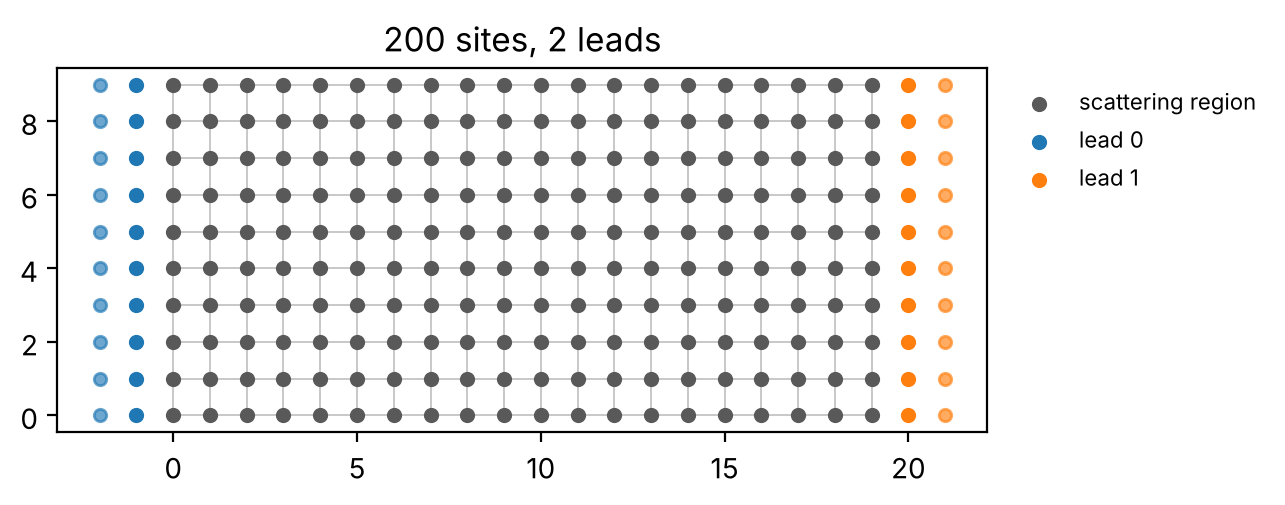

In [2]:
sq = M.square()
wire = tr.System(sq, lambda r: 0 <= r[0] < 20 and 0 <= r[1] < 10)
wire.attach_lead((-1, 0)); wire.attach_lead((1, 0))
tr.plot_system(wire);

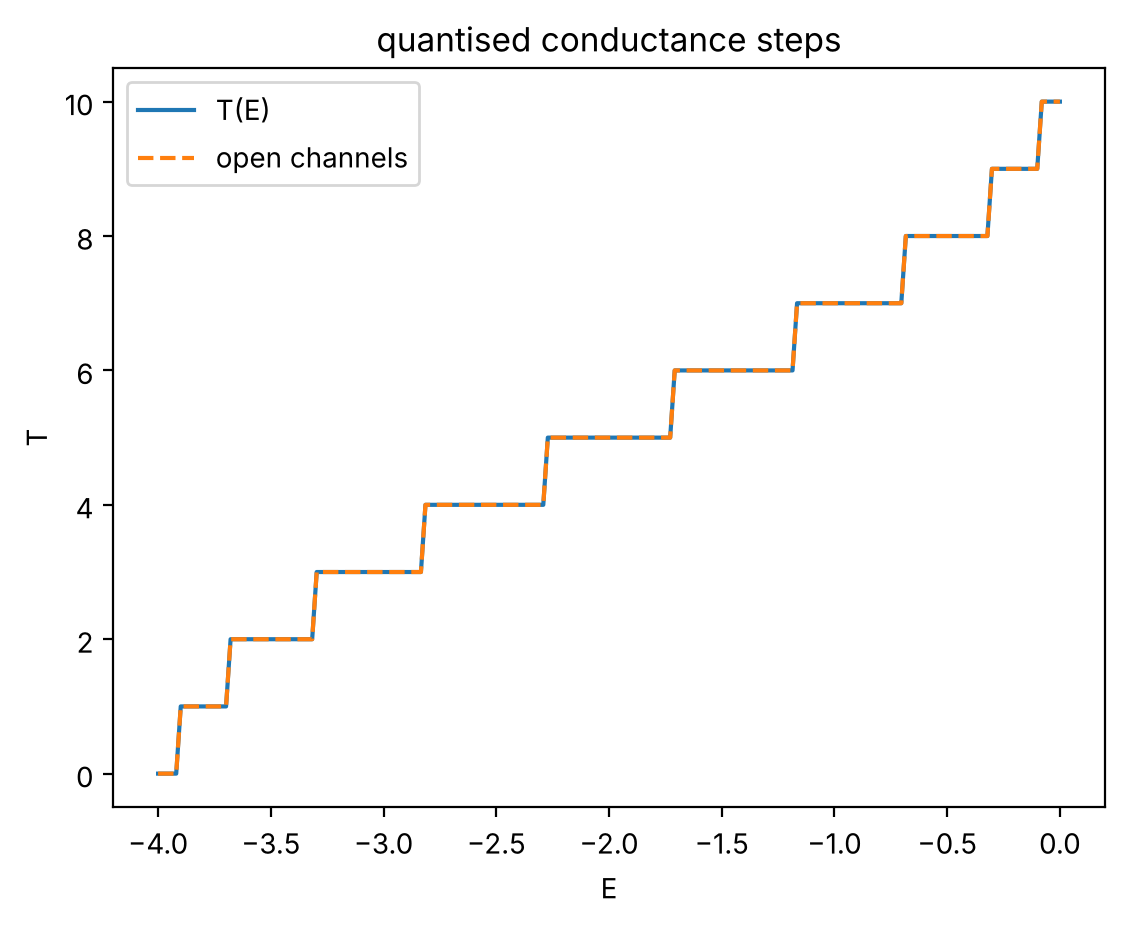

In [3]:
Es = np.linspace(-4, 0, 200)
T = wire.conductance(Es)
N = [wire.smatrix(E).num_modes(0) for E in Es]
plt.plot(Es, T, label="T(E)"); plt.plot(Es, N, "--", label="open channels")
plt.xlabel("E"); plt.ylabel("T"); plt.legend(); plt.title("quantised conductance steps");

## 2. Inside a lead: bands, modes, self-energy
The surface Green's function of a 1D chain has the closed form $g=(E-i\sqrt{4-E^2})/2$:

-1.5 (-0.75-0.661438j) (-0.75-0.661438j)
0.3 (0.15-0.988686j) (0.15-0.988686j)
1.9 (0.95-0.31225j) (0.95-0.31225j)
right-moving modes at E=-2.5: 4


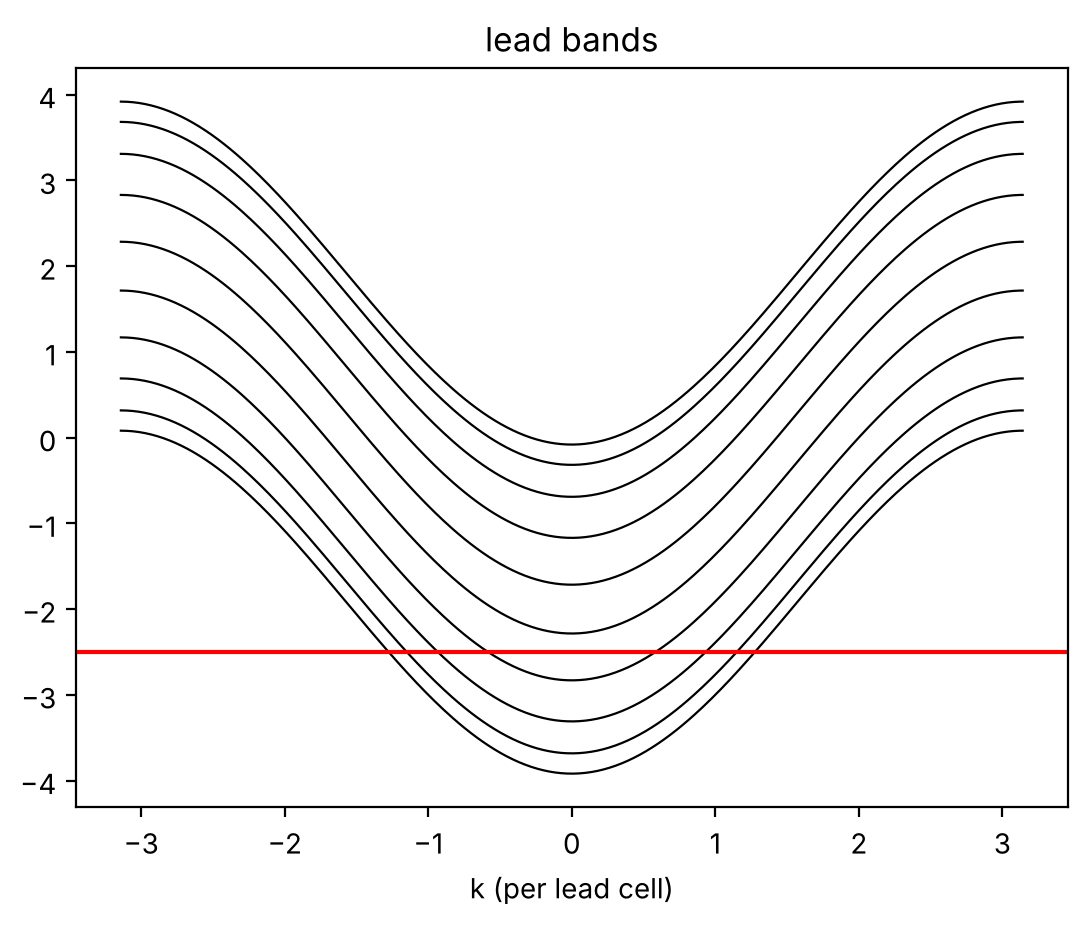

In [4]:
ch = tr.System(M.chain(), lambda r: 0 <= r[0] < 5); ch.attach_lead((-1,))
for E in (-1.5, 0.3, 1.9):
    print(E, np.round(ch.leads[0].surface_green(E)[0, 0], 6), np.round((E - 1j*np.sqrt(4 - E**2))/2, 6))
L = wire.leads[0]
k = np.linspace(-np.pi, np.pi, 300)
plt.plot(k, L.bands(k), "k", lw=0.8); plt.axhline(-2.5, c="r"); plt.xlabel("k (per lead cell)"); plt.title("lead bands")
print("right-moving modes at E=-2.5:", L.num_modes(-2.5))

## 3. A quantum point contact (any shape)
The region is flood-filled from `start` through the hoppings while `shape(pos)` is True.

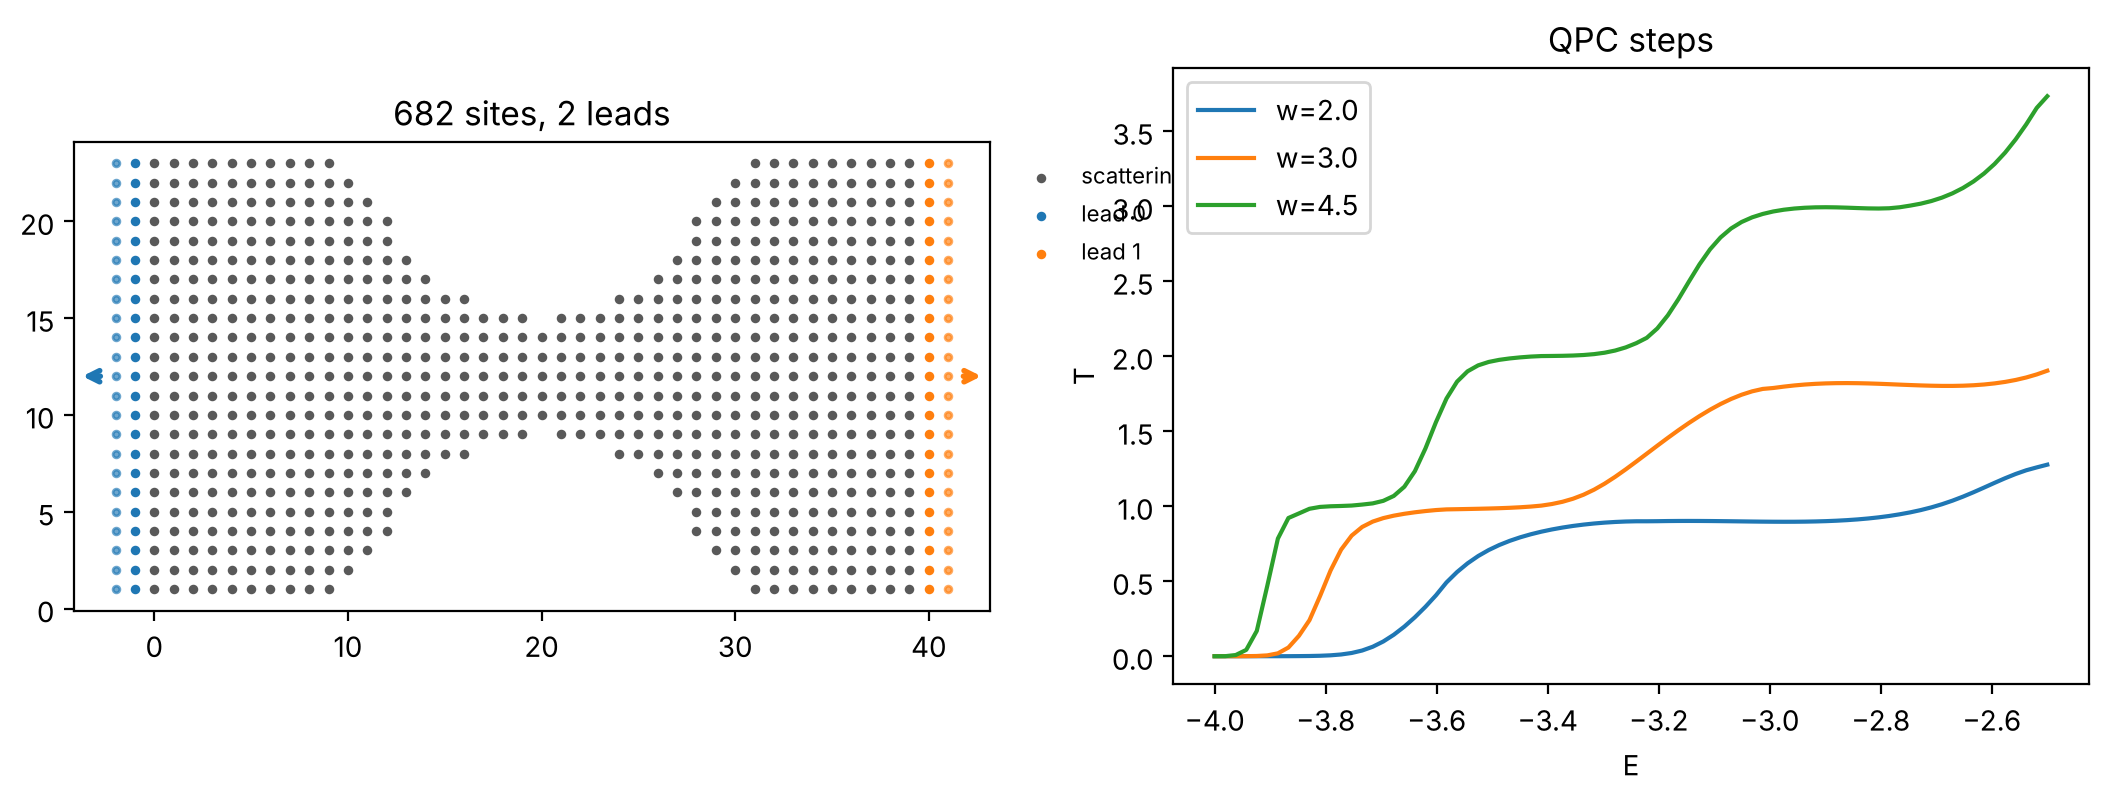

In [5]:
def qpc(r, w=3.0):
    x, y = r[0] - 20, r[1] - 12
    return 0 <= r[0] < 40 and abs(y) < 12 and (abs(y) < w + 0.08 * x**2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
s = tr.System(sq, qpc, start=(20, 12)); s.attach_lead((-1, 0)); s.attach_lead((1, 0))
tr.plot_system(s, ax=axes[0], bonds=False)
for w in (2.0, 3.0, 4.5):
    sw = tr.System(sq, lambda r, w=w: qpc(r, w), start=(20, 12)); sw.attach_lead((-1, 0)); sw.attach_lead((1, 0))
    Es = np.linspace(-4, -2.5, 80)
    axes[1].plot(Es, sw.conductance(Es), label=f"w={w}")
axes[1].legend(); axes[1].set_xlabel("E"); axes[1].set_ylabel("T"); axes[1].set_title("QPC steps");

## 4. Unitarity and reciprocity

In [6]:
sd = tr.System(sq, lambda r: 0 <= r[0] < 20 and 0 <= r[1] < 10, onsite=tr.anderson(2.0, seed=1))
sd.attach_lead((-1, 0)); sd.attach_lead((1, 0))
S = sd.smatrix(-1.0)
print("T_10 =", S.transmission(1, 0), " T_01 =", S.transmission(0, 1))
print("T + R =", S.transmission(1, 0) + S.transmission(0, 0), " = N =", S.num_modes(0))

T_10 = 2.6055219613633733  T_01 = 2.6055219613633755
T + R = 7.0  = N = 7


## 5. Disorder averaging and Anderson localisation
$\langle\ln T\rangle$ decays linearly with length in the localised regime.

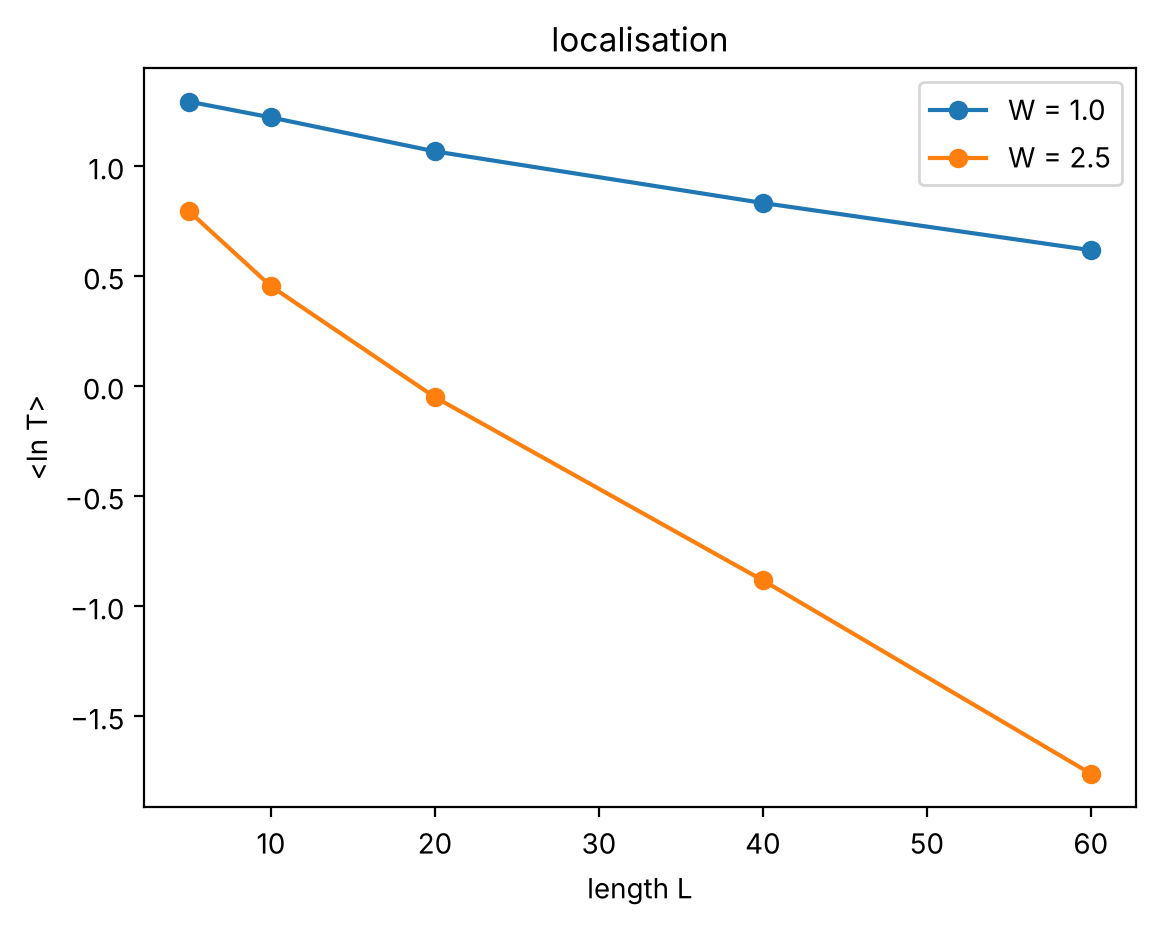

In [7]:
lengths = [5, 10, 20, 40, 60]
for W in (1.0, 2.5):
    lnT = []
    for Lx in lengths:
        vals = []
        for seed in range(8):
            s = tr.System(sq, lambda r, Lx=Lx: 0 <= r[0] < Lx and 0 <= r[1] < 6, onsite=tr.anderson(W, seed=seed))
            s.attach_lead((-1, 0)); s.attach_lead((1, 0))
            vals.append(np.log(s.transmission(1, 0, -1.0)))
        lnT.append(np.mean(vals))
    plt.plot(lengths, lnT, "o-", label=f"W = {W}")
plt.xlabel("length L"); plt.ylabel("<ln T>"); plt.legend(); plt.title("localisation");

## 6. Graphene: zigzag vs armchair nanoribbon junctions

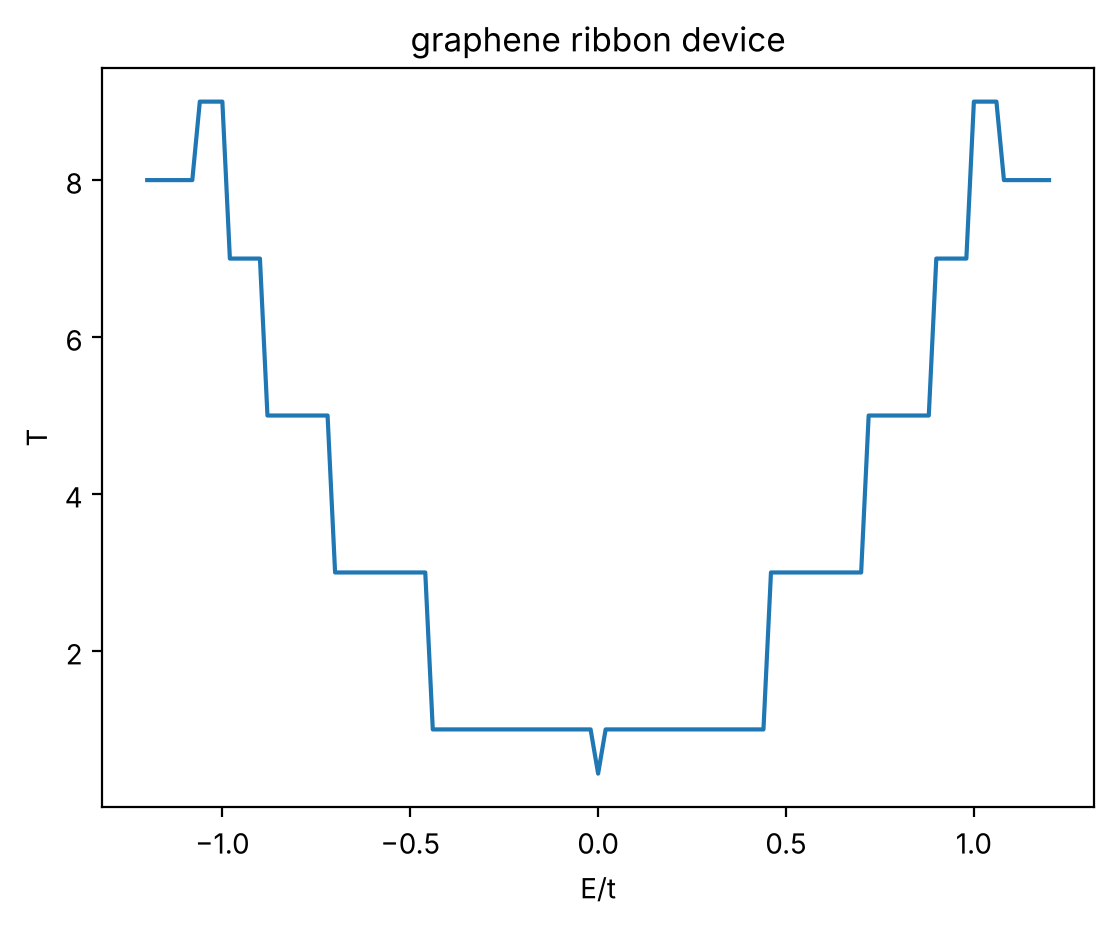

In [8]:
g = M.honeycomb()
gs = tr.System(g, lambda r: 0 <= r[0] < 20 and 0 <= r[1] < 8)
gs.attach_lead((-1, 0)); gs.attach_lead((1, 0))
Es = np.linspace(-1.2, 1.2, 121)
plt.plot(Es, gs.conductance(Es)); plt.xlabel("E/t"); plt.ylabel("T"); plt.title("graphene ribbon device");

## Exercises
1. Put a Gaussian potential bump in the wire (`onsite=`) and watch resonances in T(E).
2. Measure the localisation length versus width for W = 2.
3. Build a ring (Aharonov-Bohm) with a magnetic field (see notebook 09) and plot T versus flux.

---
## Quiz 08: Scattering and leads

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(8)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 08: Scattering regions, leads and Landauer conductance ===

Q1. In the Landauer picture, the two-terminal conductance of a coherent conductor is
   (a) G = 0 for ballistic systems
   (b) G = (e^2/h) T
   (c) G = sigma A / L always
   (d) G = (e^2/h) N^2

Q2. A perfect ballistic wire with N open channels has
   (a) T = N/2
   (b) T = 1
   (c) T depending on length
   (d) T = N

Q3. The number of open channels in a lead at energy E equals
   (a) the DOS
   (b) the number of right-moving propagating modes at E
   (c) the number of bands
   (d) the number of sites

Q4. The self-energy Sigma of a lead
   (a) is Hermitian
   (b) is zero inside the band
   (c) depends on the scattering region
   (d) has an anti-Hermitian part Gamma = i(Sigma - Sigma^dag) describing escape into the lead

Q5. The Caroli formula for the transmission from lead j to lead i is
   (a) T = Tr[Sigma]
   (b) T = Tr[G]
   (c) T = Tr[Gamma_i G Gamma_j G^dag]
   (d) T = |G_ij|

Q6. The surface Green's function of

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0